## Part 4: Create Lifetime classes
#### 1. Analyze the lifetime distribution

In [89]:
import pandas as pd
# read data from csv
debris_df = pd.read_csv('../Data/DS_combined.csv')

In [90]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID           int64
INTLDES               object
SATNAME               object
OBJECT_TYPE           object
COUNTRY               object
SITE                  object
LAUNCH                object
DECAY                 object
PERIAPSIS            float64
APOAPSIS             float64
ARG_OF_PERICENTER    float64
MEAN_MOTION          float64
ECCENTRICITY         float64
INCLINATION          float64
RA_OF_ASC_NODE       float64
MEAN_ANOMALY         float64
REV_AT_EPOCH         float64
BSTAR                float64
MEAN_MOTION_DOT      float64
MEAN_MOTION_DDOT     float64
SEMIMAJOR_AXIS       float64
PERIOD               float64
LIFETIME              object
dtype: object


In [91]:
# convert object-type columns to datetime (LAUNCH, DECAY)
debris_df['LAUNCH'] = pd.to_datetime(debris_df['LAUNCH'])
debris_df['DECAY'] = pd.to_datetime(debris_df['DECAY'])
# Remove ' days' from LIFETIME column and convert to float
debris_df['LIFETIME'] = debris_df['LIFETIME'].str.replace(' days', '').astype(int)


In [92]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())
print("Median: ", debris_df['LIFETIME'].median())

count    24199.000000
mean      3619.664284
std       4810.933231
min          0.000000
25%         44.000000
50%       1000.000000
75%       5926.500000
max      23115.000000
Name: LIFETIME, dtype: float64
Median:  1000.0


In [93]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())
print("Median: ", lifetime_years.median())

count    24199.000000
mean         9.910101
std         13.171617
min          0.000000
25%          0.120465
50%          2.737851
75%         16.225873
max         63.285421
Name: LIFETIME, dtype: float64
Median:  2.737850787132101


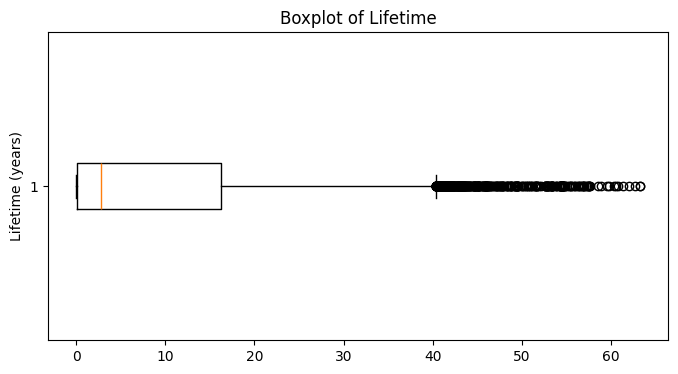

In [94]:
# create a boxplot of the lifetime in years
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.ylabel('Lifetime (years)')
plt.title('Boxplot of Lifetime')
plt.show()


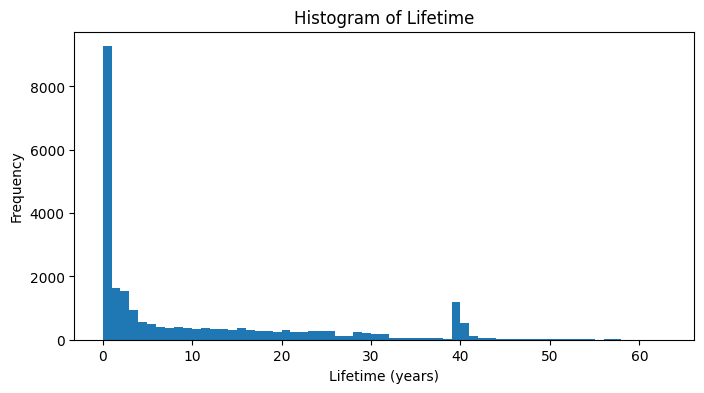

In [95]:
# create histogram of lifetime in years
import numpy as np
plt.figure(figsize=(8, 4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.show()


In [96]:
# count objects that have lifetime of less than 365 days
print("Objects with lifetime shorter than one year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])

Objects with lifetime shorter than one year:  9265


#### It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.
#### 2. Create lifetime classes

In [97]:
# divide the data into three classes based on lifetime
# Calculate the 33rd and 66th percentiles
percentile_33 = debris_df['LIFETIME'].quantile(0.33)
percentile_66 = debris_df['LIFETIME'].quantile(0.66)

# Create a function to classify the lifetime
def classify_lifetime(lifetime):
    if lifetime <= percentile_33:
        return 1
    elif lifetime <= percentile_66:
        return 2
    else:
        return 3

# Apply the function to create a new column 'class'
debris_df['LIFETIME_CLASS'] = debris_df['LIFETIME'].apply(classify_lifetime)

# print the number of objects in each class and the borders
print(debris_df['LIFETIME_CLASS'].value_counts())
print("Class 1: ", percentile_33, " days")
print("Class 2: ", percentile_66, " days")

LIFETIME_CLASS
3    8227
1    7995
2    7977
Name: count, dtype: int64
Class 1:  174.0  days
Class 2:  3648.0  days


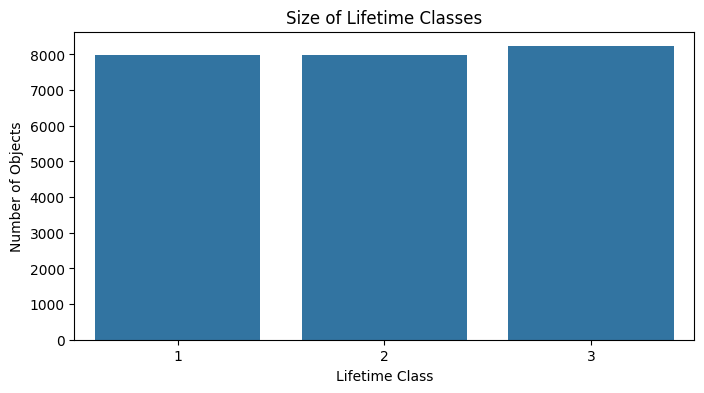

In [98]:
import seaborn as sns

# visualize the classes
plt.figure(figsize=(8,4))
sns.countplot(x='LIFETIME_CLASS', data=debris_df)
plt.title("Size of Lifetime Classes")
plt.xlabel("Lifetime Class")
plt.ylabel("Number of Objects")
plt.show()

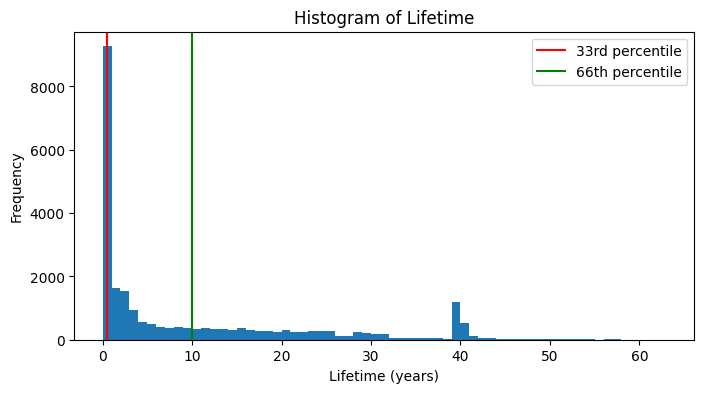

In [99]:
# visualize the class borders in the bar chart of lifetime
plt.figure(figsize=(8,4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.axvline(percentile_33/365, color='red', label='33rd percentile')
plt.axvline(percentile_66/365, color='green', label='66th percentile')
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.legend()
plt.show()

In [100]:
# remove the lifetime column since it is no longer needed
debris_df = debris_df.drop(columns=['LIFETIME'])

In [101]:
# save to csv
debris_df.to_csv('../Data/DS_combined_final.csv', index=False)